# HW 2: Agent-Based Modeling of Pandemic Spread

**Objective:** Develop an agent-based model to simulate epidemic spread and explore the impact of interventions, such as social distancing, on infection and recovery.

## A. Building the Base Model: Infection Dynamics in a Population

### i. Environment and initial conditions

- Create a bounded 20 × 20 grid representing an area where individuals (agents) move and interact.
- Place 200 agents at random cells, in the following states:
  - 195 susceptible (S) agents: individuals at risk of infection;
  - 5 infected (I) agents: individuals who can transmit the infection;
  - 0 recovered (R) agents: individuals who have recovered and are immune.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

SUSCEPTIBLE, INFECTED, RECOVERED = 0, 1, 2


### ii. Agent behaviors

- *Movement:* At each time step, each agent moves to a neighboring cell (up, down, left or right) or stays in place, at random (a random walk). Agents cannot leave the grid. You may also try other movement rules, e.g., a Lévy walk.
- *Transmission:* If a susceptible agent shares a cell with at least one infected agent, it becomes infected with probability $p$.
- *Recovery:* At each time step, each infected agent recovers with probability $q$ and becomes immune.

In [2]:
def simulate_sir(grid_size=20, population=200, initial_infected=5,
                 p=0.3, q=0.02, steps=300, seed=42):
    """Simulate synchronous movement, infection, and recovery on a square grid."""
    for name, value in [("grid_size", grid_size), ("population", population),
                        ("initial_infected", initial_infected), ("steps", steps)]:
        if not isinstance(value, (int, np.integer)):
            raise ValueError(f"{name} must be an integer")
    if grid_size < 1 or population < 1 or steps < 0:
        raise ValueError("Grid size and population must be positive; steps must be nonnegative")
    if not 0 <= initial_infected <= population:
        raise ValueError("initial_infected must be between 0 and population")
    if not (0 <= p <= 1 and 0 <= q <= 1):
        raise ValueError("p and q must be between 0 and 1")

    rng = np.random.default_rng(seed)
    positions = rng.integers(0, grid_size, size=(population, 2))
    states = np.full(population, SUSCEPTIBLE, dtype=int)
    states[:initial_infected] = INFECTED
    moves = np.array([[0, 0], [1, 0], [-1, 0], [0, 1], [0, -1]])

    counts = np.zeros((steps + 1, 3), dtype=int)
    counts[0] = np.bincount(states, minlength=3)

    for step in range(1, steps + 1):
        proposed = positions + moves[rng.integers(len(moves), size=population)]
        valid = np.all((proposed >= 0) & (proposed < grid_size), axis=1)
        positions[valid] = proposed[valid]

        susceptible = states == SUSCEPTIBLE
        infected = states == INFECTED
        recovered = states == RECOVERED

        cell_ids = positions[:, 0] * grid_size + positions[:, 1]
        infectious_cells = np.unique(cell_ids[infected])
        exposed = susceptible & np.isin(cell_ids, infectious_cells)
        new_infections = exposed & (rng.random(population) < p)
        new_recoveries = infected & (rng.random(population) < q)

        next_states = states.copy()
        next_states[new_infections] = INFECTED
        next_states[new_recoveries] = RECOVERED
        assert np.all(next_states[recovered] == RECOVERED)
        assert np.all((positions >= 0) & (positions < grid_size))
        states = next_states
        counts[step] = np.bincount(states, minlength=3)

    return counts


In [3]:
check = simulate_sir(seed=123)
assert check.shape == (301, 3)
assert np.array_equal(check[0], [195, 5, 0])
assert np.all(check.sum(axis=1) == 200)
assert np.all(check >= 0)
assert np.all(np.diff(check[:, SUSCEPTIBLE]) <= 0)
assert np.all(np.diff(check[:, RECOVERED]) >= 0)
assert np.array_equal(check, simulate_sir(seed=123))

no_transmission = simulate_sir(p=0, seed=123)
assert np.all(no_transmission[:, SUSCEPTIBLE] == 195)
no_recovery = simulate_sir(q=0, seed=123)
assert np.all(no_recovery[:, RECOVERED] == 0)
no_infection = simulate_sir(initial_infected=0, seed=123)
assert np.all(no_infection == [200, 0, 0])

one_cell = simulate_sir(grid_size=1, population=2, initial_infected=1,
                        p=1, q=1, steps=3, seed=123)
assert np.array_equal(one_cell, [[1, 1, 0], [0, 1, 1], [0, 0, 2], [0, 0, 2]])

infection_trials = [
    simulate_sir(grid_size=1, population=6, initial_infected=5,
                 p=0.3, q=0, steps=1, seed=seed)[1, SUSCEPTIBLE] == 0
    for seed in range(1000)
]
assert abs(np.mean(infection_trials) - 0.3) < 0.06
print("All base-model checks passed.")


All base-model checks passed.


### iii. Simulation

- Simulate 300 time steps, recording the number of agents in each state at each step.
- Plot the number of agents in each state over time.

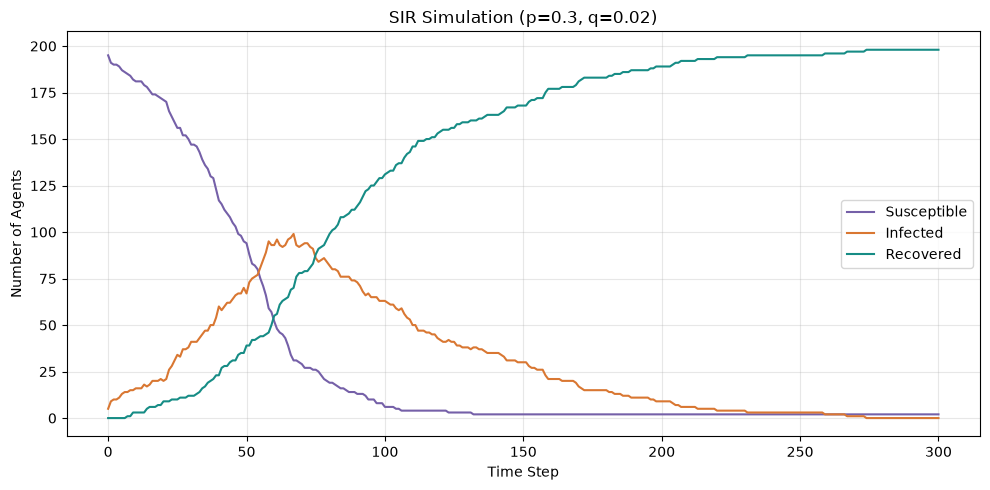

Peak infected: 99 agents at step 67
Ever infected by step 300 (including initial cases): 198
Final S, I, R: [2, 0, 198]
First step with no infected agents: 274


In [4]:
COLORS = ["#7560A8", "#D97732", "#168C85"]
LABELS = ["Susceptible", "Infected", "Recovered"]

p, q, seed = 0.3, 0.02, 42
counts = simulate_sir(p=p, q=q, seed=seed)
time = np.arange(len(counts))

fig, ax = plt.subplots(figsize=(10, 5))
for state, (label, color) in enumerate(zip(LABELS, COLORS)):
    ax.plot(time, counts[:, state], color=color, label=label)

ax.set_xlabel("Time Step")
ax.set_ylabel("Number of Agents")
ax.set_title(f"SIR Simulation (p={p}, q={q})")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/part_a_base_sir.png", dpi=200, bbox_inches="tight")
plt.show()

infected = counts[:, INFECTED]
peak_step = int(np.argmax(infected))
extinction_steps = np.flatnonzero(infected == 0)
print(f"Peak infected: {infected[peak_step]} agents at step {peak_step}")
print(f"Ever infected by step 300 (including initial cases): {200 - counts[-1, SUSCEPTIBLE]}")
print(f"Final S, I, R: {counts[-1].tolist()}")
if extinction_steps.size:
    print(f"First step with no infected agents: {extinction_steps[0]}")
else:
    print("The outbreak has not ended by step 300.")
